In [1]:
# Celula 1: prepara o ambiente de trabalho para toda a analise.
# - pandas/numpy: manipulacao de dados
# - matplotlib: graficos
# - scikit-learn: validacao cruzada e metricas
# - xgboost: modelo de classificacao
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import TimeSeriesSplit
# from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    brier_score_loss,
    log_loss,
    ConfusionMatrixDisplay,
)

# Instala automaticamente o xgboost apenas se ele nao estiver disponivel.
try:
    from xgboost import XGBClassifier
except ImportError:
    import sys
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "xgboost", "-q"])
    from xgboost import XGBClassifier

# Instala automaticamente o optuna apenas se ele nao estiver disponivel.
try:
    import optuna
except ImportError:
    import sys
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "optuna", "-q"])
    import optuna

# Instala automaticamente o optuna-dashboard apenas se ele nao estiver disponivel.
try:
    import optuna_dashboard
except ImportError:
    import sys
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "optuna-dashboard", "-q"])
    import optuna_dashboard

# Mostra todas as colunas ao inspecionar DataFrames.
pd.set_option("display.max_columns", None)
print("Bibliotecas carregadas com sucesso.")

Bibliotecas carregadas com sucesso.


In [ ]:
# Celula 2: leitura da base e preparo das variaveis de entrada.
csv_path = Path("../../tabela_final/table_orders_holidays_ecommerce_events.csv") # Path(r"C:\Users\otavi\OneDrive\Desktop\last-mile-tcc\backend\tabela_final\table_orders_holidays_ecommerce_events.csv")
df = pd.read_csv(csv_path)

target_col = "delivered_on_time"
if target_col not in df.columns:
    raise ValueError(f"A coluna alvo '{target_col}' nao foi encontrada no CSV.")

# =====================================================================
# 1. ENGENHARIA DO SLA (Prazo da Transportadora - LAST MILE)
# =====================================================================
df['order_purchase_timestamp'] = pd.to_datetime(df['order_purchase_timestamp'], utc=True)
df['order_estimated_delivery_date'] = pd.to_datetime(df['order_estimated_delivery_date'], utc=True)
df['order_delivered_carrier_date'] = pd.to_datetime(df['order_delivered_carrier_date'], utc=True)

# Quantos dias a transportadora tem para entregar apos pegar o pacote?
# df['prazo_transportadora_dias'] = (df['order_estimated_delivery_date'] - df['order_delivered_carrier_date']).dt.days

df['order_estimated_delivery_date'] = pd.to_datetime(
    df['order_estimated_delivery_date'], utc=True
)

df['order_delivered_carrier_date'] = pd.to_datetime(
    df['order_delivered_carrier_date'], utc=True
)

# Mesmo critério do PySpark: diferença entre datas
df['prazo_transportadora_dias'] = (
    df['order_estimated_delivery_date'].dt.normalize() -
    df['order_delivered_carrier_date'].dt.normalize()
).dt.days

print(
    "Pedidos já atrasados:",
    (df['prazo_transportadora_dias'] < 0).sum()
)



# Remover os casos onde a transportadora nunca pegou o pacote para evitar NaN no treino
df = df.dropna(subset=['prazo_transportadora_dias']).copy()

# Extraindo o mes da compra (sazonalidade - Black Friday, Natal)
# df['purchase_month'] = df['order_purchase_timestamp'].dt.month
df['carrier_month'] = df['order_delivered_carrier_date'].dt.month

# =====================================================================
# 1b. FEATURES DE INTERAÇÃO (Adicionadas para aumentar o sinal)
# =====================================================================
df['prazo_por_km'] = df['prazo_transportadora_dias'] / (df['distance_km'] + 1)
df['frete_por_kg'] = df['freight_value'] / (df['product_weight_g'] / 1000 + 0.1)
df['densidade_produto'] = df['product_weight_g'] / (df['volume_cm3'] + 1)

# =====================================================================
# 2. ORDENAÇÃO CRONOLÓGICA (Baseada no momento da coleta)
# =====================================================================
df = df.sort_values('order_delivered_carrier_date').reset_index(drop=True)

# Divide em treino/teste com split temporal (Passado treina, Futuro testa).
# Treino: ate Junho de 2018 | Teste: Julho de 2018 em diante.
date_col = df['order_delivered_carrier_date'].copy()
split_date = pd.to_datetime("2018-07-01", utc=True)

leakage_candidates = [
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "shipping_delay_hours",
    "delivery_time_days",
    "review_score",
]
leakage_cols = [c for c in leakage_candidates if c in df.columns]

# Separa previsores e alvo.
feature_cols = [c for c in df.columns if c != target_col and c not in leakage_cols]
X = df[feature_cols].copy()
# Inverte o alvo: atraso = 1, no prazo = 0.
y = (~df[target_col].astype(bool)).astype(int).copy()

colunas_remover = [
    "order_purchase_timestamp",
    "order_approved_at",
    "interval_code_delivered_carrier", # variável n ajudou no modelo
    "interval_code_delivered_customer",
    "order_estimated_delivery_date", # Ja usamos
    "shipping_limit_date",
    "delivered_on_time",
    "review_score",
    
    # --- FEATURES REDUNDANTES / BAIXA INFLUENCIA REMOVIDAS ---
    "is_holiday_in_7_days",
    "is_holiday_in_14_days",
    "had_holiday_7_days_ago",
    "had_holiday_14_days_ago",
    "holiday_at_purchase",
    "is_weekend",

    # --- TESTE: Remocao de cidades e category_name ---
    "customer_city",
    "seller_city",
    "category_name",
    # "same_city",
]

X = X.drop(columns=colunas_remover, errors='ignore')

cat_cols = []  # Sem variaveis categoricas para este teste

train_mask = date_col < split_date
test_mask = date_col >= split_date

X_train = X[train_mask].copy()
y_train = y[train_mask].copy()
X_test = X[test_mask].copy()
y_test = y[test_mask].copy()

num_cols = list(X_train.columns)
scaler = None  # Arvores de decisao (XGBoost) nao necessitam de normalizacao

pos_count = int((y_train == 1).sum())
total_linhas = len(X)
qtd_treino = len(X_train)
qtd_teste = len(X_test)

print(f"Total de registros: Linhas: {X.shape[0]:,} | Colunas: {X.shape[1]}\n")
print(f"Treino (ate Jun/2018): {qtd_treino:,} ({qtd_treino/total_linhas:.2%})")
print(f" - Atrasos no Treino: {pos_count} ({(y_train == 1).mean():.2%} do treino)\n")
print(f"Teste (Jul/2018 em diante): {qtd_teste:,} ({qtd_teste/total_linhas:.2%})")
print(f" - Atrasos no Teste: {(y_test == 1).sum()} ({(y_test == 1).mean():.2%} do teste)\n")

X_test.head()

Pedidos já atrasados: 0
Total de registros: Linhas: 33,603 | Colunas: 23

Treino (ate Jun/2018): 28,603 (85.12%)
 - Atrasos no Treino: 1322 (4.62% do treino)

Teste (Jul/2018 em diante): 5,000 (14.88%)
 - Atrasos no Teste: 499 (9.98% do teste)



,holiday_at_carrier,days_since_last_holiday,days_until_next_holiday,ecommerce_event_at_carrier,days_since_last_ecommerce_event,days_until_next_ecommerce_event,is_ecommerce_event_in_7_days,is_ecommerce_event_in_14_days,had_ecommerce_event_7_days_ago,had_ecommerce_event_14_days_ago,purchase_hour,purchase_day_of_week,price,freight_value,product_weight_g,volume_cm3,distance_km,same_city,prazo_transportadora_dias,carrier_month,prazo_por_km,frete_por_kg,densidade_produto
28603,0,32,7,0,50,41,0,0,0,0,15,5,58.99,13.07,200,3960.0,65.936,0,17,7,0.253974,43.566667,0.050492
28604,0,32,7,0,50,41,0,0,0,0,20,5,24.99,13.76,2350,10648.0,411.255,0,17,7,0.041237,5.616327,0.220678
28605,0,32,7,0,50,41,0,0,0,0,10,6,119.90,13.50,459,3276.0,284.778,0,21,7,0.073484,24.150268,0.140067
28606,0,32,7,0,50,41,0,0,0,0,8,6,49.00,13.00,250,640.0,221.179,0,18,7,0.081016,37.142857,0.390016
28607,0,32,7,0,50,41,0,0,0,0,14,5,106.00,17.95,3305,35100.0,112.930,0,11,7,0.096551,5.271659,0.094157


In [3]:
# Celula 3: Instalação do imbalanced-learn, funcoes de metricas e definicao do SMOTENC.
try:
    import imblearn
except ImportError:
    import sys
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "imbalanced-learn", "-q"])
    import imblearn

from imblearn.over_sampling import SMOTENC, SMOTE
from pandas.api.types import is_bool_dtype, is_object_dtype

# A avaliacao desta analise trata "atraso" como classe positiva (1).
def metricas_atraso(y_true, y_pred_atraso, y_proba_atraso):
    return {
        "accuracy_atraso": accuracy_score(y_true, y_pred_atraso),
        "precision_atraso": precision_score(y_true, y_pred_atraso, zero_division=0),
        "recall_atraso": recall_score(y_true, y_pred_atraso, zero_division=0),
        "f1_atraso": f1_score(y_true, y_pred_atraso, zero_division=0),
        "f2_atraso": fbeta_score(y_true, y_pred_atraso, beta=2, zero_division=0),
        "roc_auc_atraso": roc_auc_score(y_true, y_proba_atraso),
        "pr_auc_atraso": average_precision_score(y_true, y_proba_atraso),
        "balanced_accuracy_atraso": balanced_accuracy_score(y_true, y_pred_atraso),
        "mcc_atraso": matthews_corrcoef(y_true, y_pred_atraso),
        "brier_score_atraso": brier_score_loss(y_true, y_proba_atraso),
        "log_loss_atraso": log_loss(y_true, y_proba_atraso),
    }

def metricas_gerais(y_true, y_pred, y_proba):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_proba),
        "PR-AUC": average_precision_score(y_true, y_proba),
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "MCC": matthews_corrcoef(y_true, y_pred),
        "Brier Score": brier_score_loss(y_true, y_proba),
        "Log Loss": log_loss(y_true, y_proba),
    }

CATEGORICAS_EXPLICITAS = {
    "holiday_at_carrier",
    "ecommerce_event_at_carrier",
    "is_ecommerce_event_in_7_days",
    "is_ecommerce_event_in_14_days",
    "had_ecommerce_event_7_days_ago",
    "had_ecommerce_event_14_days_ago",
    "purchase_hour",
    "purchase_day_of_week",
    "same_city"
}

def identificar_categoricas(X_ref):
    categorias = []
    for coluna in X_ref.columns:
        serie = X_ref[coluna]
        if (coluna in CATEGORICAS_EXPLICITAS or is_bool_dtype(serie)
            or is_object_dtype(serie) or isinstance(serie.dtype, pd.CategoricalDtype)):
            categorias.append(coluna)
    return categorias

smotenc_cat_cols = identificar_categoricas(X_train)
print("Features categoricas para SMOTENC:", smotenc_cat_cols)

def aplicar_smotenc(X_parte, y_parte, cat_cols=[], ratio="auto", random_state=42):
    if X_parte.isna().any().any():
        raise ValueError("Existem valores ausentes: trate-os antes de aplicar SMOTENC.")
    if not all(pd.api.types.is_numeric_dtype(t) for t in X_parte.dtypes):
        raise ValueError("Existem features nao numericas: codifique-as antes do treino.")
    
    n_min = int(y_parte.value_counts().min())
    if n_min < 2:
        raise ValueError("SMOTE/SMOTENC exige pelo menos 2 exemplos na classe minoritaria.")
    k = min(5, n_min - 1)
    
    if cat_cols:
        sampler = SMOTENC(categorical_features=[X_parte.columns.get_loc(c) for c in cat_cols],
                          sampling_strategy=ratio, random_state=random_state, k_neighbors=k)
    else:
        # Fallback caso a lista venha vazia por qualquer motivo
        sampler = SMOTE(sampling_strategy=ratio, random_state=random_state, k_neighbors=k)
        
    X_res, y_res = sampler.fit_resample(X_parte, y_parte)
    return pd.DataFrame(X_res, columns=X_parte.columns), pd.Series(y_res, name=y_parte.name)

# Configuracao do Optuna para busca de hiperparametros.
n_trials = 50
study_seed = 42
cv_tune = TimeSeriesSplit(n_splits=5)
threshold_grid_tune = np.arange(0.05, 0.86, 0.01)

# Vetor binario: 1 = atraso, 0 = nao atraso.
y_train_atraso = y_train.values

print("Preparacao concluida.")

Features categoricas para SMOTENC: ['holiday_at_carrier', 'ecommerce_event_at_carrier', 'is_ecommerce_event_in_7_days', 'is_ecommerce_event_in_14_days', 'had_ecommerce_event_7_days_ago', 'had_ecommerce_event_14_days_ago', 'purchase_hour', 'purchase_day_of_week', 'same_city']
Preparacao concluida.


In [4]:
# Celula 4: busca de hiperparametros com Optuna + SMOTENC (SEM early_stopping_rounds).
# Otimizacao baseada estritamente no F1-Score.
optuna_db_path = Path("optuna_xgb_temporal.db").resolve()
study_storage = f"sqlite:///{optuna_db_path.as_posix()}"
study_name = "xgb_temporal_lastmile_smotenc_v4"

def objective(trial):
    # Proporcao de oversampling sintetico via SMOTE (0.2 [20% de pos pra 1 neg] ate 1.0 [1:1])
    smote_ratio = trial.suggest_float("smote_ratio", 0.2, 1.0, step=0.2)

    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 300, step=50),
        "max_depth": trial.suggest_int("max_depth", 2, 4),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1),
        "subsample": trial.suggest_float("subsample", 0.5, 0.8),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 0.8),
        "min_child_weight": trial.suggest_int("min_child_weight", 10, 50),
        "gamma": trial.suggest_float("gamma", 1.0, 5.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 0.5, 5.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 2.0, 10.0)
    }
    oof_proba_atraso = np.zeros(len(y_train), dtype=float)
    val_mask = np.zeros(len(y_train), dtype=bool)

    for fold, (tr_idx, va_idx) in enumerate(cv_tune.split(X_train, y_train), start=1):
        X_tr, X_va = X_train.iloc[tr_idx], X_train.iloc[va_idx]
        y_tr, y_va = y_train.iloc[tr_idx], y_train.iloc[va_idx]

        # Aplica SMOTENC APENAS no subset de treino do fold atual.
        X_tr_smote, y_tr_smote = aplicar_smotenc(
            X_tr, y_tr,
            cat_cols=smotenc_cat_cols,
            ratio=smote_ratio,
            random_state=1000 + trial.number * 10 + fold
        )

        # Treinamento sem early stopping
        mdl = XGBClassifier(
            objective="binary:logistic",
            eval_metric="aucpr",
            random_state=1000 + trial.number * 10 + fold,
            n_jobs=-1,
            tree_method="hist",
            enable_categorical=True,
            **params,
        )
        
        mdl.fit(X_tr_smote, y_tr_smote, verbose=False)

        proba_atraso_va = mdl.predict_proba(X_va)[:, 1]
        oof_proba_atraso[va_idx] = proba_atraso_va
        val_mask[va_idx] = True

    y_val_real = y_train_atraso[val_mask]
    oof_proba_val = oof_proba_atraso[val_mask]

    pr_auc_i = float(average_precision_score(y_val_real, oof_proba_val))

    best_thr_i = 0.50
    best_f1_i = -1.0
    best_recall_i = -1.0
    best_precision_i = -1.0

    for thr in threshold_grid_tune:
        pred_atraso = (oof_proba_val >= thr).astype(int)
        precision_i = precision_score(y_val_real, pred_atraso, zero_division=0)
        recall_i = recall_score(y_val_real, pred_atraso, zero_division=0)
        f1_i = f1_score(y_val_real, pred_atraso, zero_division=0)

        if (f1_i > best_f1_i) or (np.isclose(f1_i, best_f1_i) and recall_i > best_recall_i) or (
            np.isclose(f1_i, best_f1_i) and np.isclose(recall_i, best_recall_i) and precision_i > best_precision_i
        ):
            best_f1_i = float(f1_i)
            best_recall_i = float(recall_i)
            best_precision_i = float(precision_i)
            best_thr_i = float(thr)

    trial.set_user_attr("best_threshold", best_thr_i)
    trial.set_user_attr("cv_pr_auc_atraso", pr_auc_i)
    trial.set_user_attr("cv_f1_atraso", best_f1_i)
    trial.set_user_attr("cv_recall_atraso", best_recall_i)
    trial.set_user_attr("cv_precision_atraso", best_precision_i)
    trial.set_user_attr("smote_ratio", smote_ratio)

    return best_f1_i  # Otimizar por F1

sampler = optuna.samplers.TPESampler(seed=study_seed)
study = optuna.create_study(
    direction="maximize",
    sampler=sampler,
    study_name=study_name,
    load_if_exists=True,
)
study.optimize(objective, n_trials=n_trials, show_progress_bar=False)

best_trial = study.best_trial
best_params_all = best_trial.params.copy()
best_smote_ratio_v4 = float(best_params_all.pop("smote_ratio"))
best_params_v4 = best_params_all
best_threshold_v4 = float(best_trial.user_attrs["best_threshold"])

tuning_rows = []
for t in study.trials:
    if t.value is None:
        continue
    tuning_rows.append({
        "candidate": t.number + 1,
        "cv_f1_atraso": t.user_attrs.get("cv_f1_atraso", np.nan),
        "cv_pr_auc_atraso": t.user_attrs.get("cv_pr_auc_atraso", np.nan),
        "cv_recall_atraso": t.user_attrs.get("cv_recall_atraso", np.nan),
        "cv_precision_atraso": t.user_attrs.get("cv_precision_atraso", np.nan),
        "smote_ratio": t.user_attrs.get("smote_ratio", np.nan),
        "best_threshold": t.user_attrs.get("best_threshold", np.nan),
        "params": t.params,
    })

df_tuning = pd.DataFrame(tuning_rows).sort_values(
    ["cv_f1_atraso", "cv_pr_auc_atraso", "cv_recall_atraso", "cv_precision_atraso"], ascending=False
).reset_index(drop=True)

print(f"Trials avaliados: {len(df_tuning)}")
print("Top 8 configuracoes pela validacao cruzada (F1 -> PR-AUC -> Recall):")
display(df_tuning.head(8))
print("\nMelhores hiperparametros encontrados (Otimizado por F1):")
print(f" - SMOTE Ratio: {best_smote_ratio_v4} (Positivos:Negativos)")
for key, value in best_params_v4.items():
    print(f" - {key}: {value}")
print(f"Melhor limiar (Optuna - Foco F1): {best_threshold_v4:.2f}")
print(f"Study name: {study_name}")
print(f"Comando dashboard: optuna-dashboard {study_storage} --port 8080")

[I 2026-10-15 20:04:56,060] A new study created in memory with name: xgb_temporal_lastmile_smotenc_v4
[I 2026-10-15 20:05:08,851] Trial 0 finished with value: 0.16969147005444646 and parameters: {'smote_ratio': 0.4, 'n_estimators': 300, 'max_depth': 4, 'learning_rate': 0.0638792635777333, 'subsample': 0.5468055921327309, 'colsample_bytree': 0.5467983561008608, 'min_child_weight': 12, 'gamma': 4.46470458309974, 'reg_alpha': 3.20501755284444, 'reg_lambda': 7.664580622368364}. Best is trial 0 with value: 0.16969147005444646.
[I 2026-10-15 20:05:21,420] Trial 1 finished with value: 0.21490626428898033 and parameters: {'smote_ratio': 0.2, 'n_estimators': 300, 'max_depth': 4, 'learning_rate': 0.029110519961044856, 'subsample': 0.5545474901621302, 'colsample_bytree': 0.5550213529560302, 'min_child_weight': 22, 'gamma': 3.0990257265289514, 'reg_alpha': 2.4437525838895207, 'reg_lambda': 4.329833121584335}. Best is trial 1 with value: 0.21490626428898033.
[I 2026-10-15 20:05:54,561] Trial 2 fini

Trials avaliados: 50
Top 8 configuracoes pela validacao cruzada (F1 -> PR-AUC -> Recall):


,candidate,cv_f1_atraso,cv_pr_auc_atraso,cv_recall_atraso,cv_precision_atraso,smote_ratio,best_threshold,params
0,35,0.268886,0.209217,0.373333,0.210105,0.2,0.25,"{'smote_ratio': 0.2, 'n_estimators': 150, 'max..."
1,50,0.268293,0.210591,0.322667,0.229602,0.2,0.31,"{'smote_ratio': 0.2, 'n_estimators': 200, 'max..."
2,45,0.266717,0.206873,0.315556,0.230969,0.2,0.30,"{'smote_ratio': 0.2, 'n_estimators': 150, 'max..."
3,43,0.264224,0.210578,0.301333,0.235253,0.2,0.30,"{'smote_ratio': 0.2, 'n_estimators': 150, 'max..."
4,32,0.261748,0.205334,0.264889,0.258681,0.2,0.29,"{'smote_ratio': 0.2, 'n_estimators': 200, 'max..."
5,27,0.259528,0.204223,0.254222,0.265060,0.2,0.35,"{'smote_ratio': 0.2, 'n_estimators': 200, 'max..."
6,34,0.258532,0.201814,0.333333,0.211149,0.2,0.26,"{'smote_ratio': 0.2, 'n_estimators': 150, 'max..."
7,33,0.256547,0.204153,0.426667,0.183416,0.2,0.23,"{'smote_ratio': 0.2, 'n_estimators': 200, 'max..."



Melhores hiperparametros encontrados (Otimizado por F1):
 - SMOTE Ratio: 0.2 (Positivos:Negativos)
 - n_estimators: 150
 - max_depth: 4
 - learning_rate: 0.01172316988272533
 - subsample: 0.5596406357298029
 - colsample_bytree: 0.5388377400883355
 - min_child_weight: 24
 - gamma: 4.480035701213472
 - reg_alpha: 2.387086890701229
 - reg_lambda: 2.3092090988693847
Melhor limiar (Optuna - Foco F1): 0.25
Study name: xgb_temporal_lastmile_smotenc_v4
Comando dashboard: optuna-dashboard sqlite:///C:/Users/otavi/OneDrive/Desktop/last-mile-tcc/backend/modelo/split-temporal/optuna_xgb_temporal.db --port 8080


Resumo do SMOTE no Treino (Ratio Positivos/Negativos = 0.2):
 - Antes : 28,603 registros | Atrasos (1): 1,322 (4.62%) | No Prazo (0): 27,281
 - Depois: 32,737 registros | Atrasos (1): 5,456 (16.67%) | No Prazo (0): 27,281

Metricas no teste (foco em atraso e F1-score):


,Teste
accuracy_atraso,0.5826
precision_atraso,0.1839
recall_atraso,0.9259
f1_atraso,0.3069
f2_atraso,0.5124
roc_auc_atraso,0.8580
pr_auc_atraso,0.4399
balanced_accuracy_atraso,0.7352
mcc_atraso,0.2820
brier_score_atraso,0.1090



Como interpretar as metricas:
- f1_atraso: media harmonica entre precision e recall (metrica principal para comparacao dos modelos).
- precision_atraso: entre os pedidos previstos como atraso, quantos realmente atrasaram.
- recall_atraso: entre os pedidos que realmente atrasaram, quantos o modelo conseguiu detectar.
- f2_atraso: semelhante ao F1, mas dando mais peso ao recall (bom para nao perder atrasos).


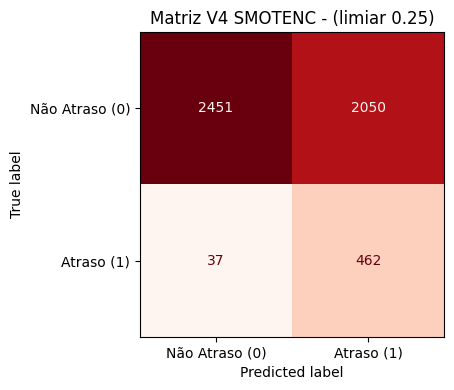

Resumo (teste):
- Proporcao SMOTENC (Pos/Neg): 0.2
- Limiar adotado: 0.25
- F1 atraso (Principal): 0.3069
- Precision atraso: 0.1839
- Recall atraso: 0.9259
- F2 atraso: 0.5124
- ROC-AUC atraso: 0.8580


In [5]:
# Celula 5: treino final do modelo aplicando SMOTENC no treino + avaliacao no teste.
X_train_smote, y_train_smote = aplicar_smotenc(
    X_train, y_train,
    cat_cols=smotenc_cat_cols,
    ratio=best_smote_ratio_v4,
    random_state=4242
)

print(f"Resumo do SMOTE no Treino (Ratio Positivos/Negativos = {best_smote_ratio_v4}):")
print(f" - Antes : {len(X_train):,} registros | Atrasos (1): {(y_train == 1).sum():,} ({(y_train == 1).mean():.2%}) | No Prazo (0): {(y_train == 0).sum():,}")
print(f" - Depois: {len(X_train_smote):,} registros | Atrasos (1): {(y_train_smote == 1).sum():,} ({(y_train_smote == 1).mean():.2%}) | No Prazo (0): {(y_train_smote == 0).sum():,}\n")

model_v4 = XGBClassifier(
    objective="binary:logistic",
    eval_metric="aucpr",
    random_state=4242,
    n_jobs=-1,
    tree_method="hist",
    enable_categorical=True,
    **best_params_v4,
)

# Treinado na base balanceada com geracao sintetica (X_train_smote) sem early_stopping.
model_v4.fit(X_train_smote, y_train_smote, verbose=False)

# Probabilidade de atraso (classe 1) avaliada nas bases completas originais de treino e teste.
y_proba_v4_train = model_v4.predict_proba(X_train)[:, 1]
y_proba_v4_test = model_v4.predict_proba(X_test)[:, 1]

y_pred_v4_train = (y_proba_v4_train >= best_threshold_v4).astype(int)
y_pred_v4_test = (y_proba_v4_test >= best_threshold_v4).astype(int)

res_v4_train = metricas_atraso(y_train, y_pred_v4_train, y_proba_v4_train)
res_v4_test = metricas_atraso(y_test, y_pred_v4_test, y_proba_v4_test)
metricas_treino_v4 = metricas_gerais(y_train, y_pred_v4_train, y_proba_v4_train)
metricas_teste_v4 = metricas_gerais(y_test, y_pred_v4_test, y_proba_v4_test)

print("Metricas no teste (foco em atraso e F1-score):")
display(pd.DataFrame(pd.Series(res_v4_test, name="Teste")).round(4))

print("\nComo interpretar as metricas:")
print("- f1_atraso: media harmonica entre precision e recall (metrica principal para comparacao dos modelos).")
print("- precision_atraso: entre os pedidos previstos como atraso, quantos realmente atrasaram.")
print("- recall_atraso: entre os pedidos que realmente atrasaram, quantos o modelo conseguiu detectar.")
print("- f2_atraso: semelhante ao F1, mas dando mais peso ao recall (bom para nao perder atrasos).")

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_v4_test, cmap="Reds", ax=ax, colorbar=False,
    display_labels=["Não Atraso (0)", "Atraso (1)"]
)
ax.set_title(f"Matriz V4 SMOTENC - (limiar {best_threshold_v4:.2f})")
plt.tight_layout()
plt.show()

print("Resumo (teste):")
print(f"- Proporcao SMOTENC (Pos/Neg): {best_smote_ratio_v4}")
print(f"- Limiar adotado: {best_threshold_v4:.2f}")
print(f"- F1 atraso (Principal): {res_v4_test['f1_atraso']:.4f}")
print(f"- Precision atraso: {res_v4_test['precision_atraso']:.4f}")
print(f"- Recall atraso: {res_v4_test['recall_atraso']:.4f}")
print(f"- F2 atraso: {res_v4_test['f2_atraso']:.4f}")
print(f"- ROC-AUC atraso: {res_v4_test['roc_auc_atraso']:.4f}")

In [6]:
# Celula 6: tabelas de metricas de atraso (classe 1).
print("=" * 120)
print("METRICAS DE ATRASO (CLASSE 1) - V4 SMOTENC")
print("=" * 120)

print("\n" + "-" * 120)
print("TREINO COMPLETO (ATRASO)")
print("-" * 120)
df_v4_train_atraso = pd.DataFrame(pd.Series(res_v4_train, name="Treino"))
display(df_v4_train_atraso.round(4))

print("\n" + "-" * 120)
print("TESTE (ATRASO)")
print("-" * 120)
df_v4_test_atraso = pd.DataFrame(pd.Series(res_v4_test, name="Teste"))
display(df_v4_test_atraso.round(4))

print("RESUMO\n")
print("─" * 120 + "\n")
print(f"  SMOTENC Ratio (Pos/Neg): {best_smote_ratio_v4} | Limiar utilizado: {best_threshold_v4:.2f}")
print(
    f"  Treino - F1 (Atraso): {res_v4_train['f1_atraso']:.4f}, Precision (Atraso): {res_v4_train['precision_atraso']:.4f}, "
    f"Recall (Atraso): {res_v4_train['recall_atraso']:.4f}, PR-AUC: {res_v4_train['pr_auc_atraso']:.4f}, ROC-AUC: {metricas_treino_v4['ROC-AUC']:.4f}"
)
print(
    f"  Teste  - F1 (Atraso): {res_v4_test['f1_atraso']:.4f}, Precision (Atraso): {res_v4_test['precision_atraso']:.4f}, "
    f"Recall (Atraso): {res_v4_test['recall_atraso']:.4f}, PR-AUC: {res_v4_test['pr_auc_atraso']:.4f}, ROC-AUC: {metricas_teste_v4['ROC-AUC']:.4f}"
)


METRICAS DE ATRASO (CLASSE 1) - V4 SMOTENC

------------------------------------------------------------------------------------------------------------------------
TREINO COMPLETO (ATRASO)
------------------------------------------------------------------------------------------------------------------------


,Treino
accuracy_atraso,0.9066
precision_atraso,0.2395
recall_atraso,0.4690
f1_atraso,0.3171
f2_atraso,0.3936
roc_auc_atraso,0.8022
pr_auc_atraso,0.3267
balanced_accuracy_atraso,0.6984
mcc_atraso,0.2904
brier_score_atraso,0.0478



------------------------------------------------------------------------------------------------------------------------
TESTE (ATRASO)
------------------------------------------------------------------------------------------------------------------------


,Teste
accuracy_atraso,0.5826
precision_atraso,0.1839
recall_atraso,0.9259
f1_atraso,0.3069
f2_atraso,0.5124
roc_auc_atraso,0.8580
pr_auc_atraso,0.4399
balanced_accuracy_atraso,0.7352
mcc_atraso,0.2820
brier_score_atraso,0.1090


RESUMO

────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────

  SMOTENC Ratio (Pos/Neg): 0.2 | Limiar utilizado: 0.25
  Treino - F1 (Atraso): 0.3171, Precision (Atraso): 0.2395, Recall (Atraso): 0.4690, PR-AUC: 0.3267, ROC-AUC: 0.8022
  Teste  - F1 (Atraso): 0.3069, Precision (Atraso): 0.1839, Recall (Atraso): 0.9259, PR-AUC: 0.4399, ROC-AUC: 0.8580


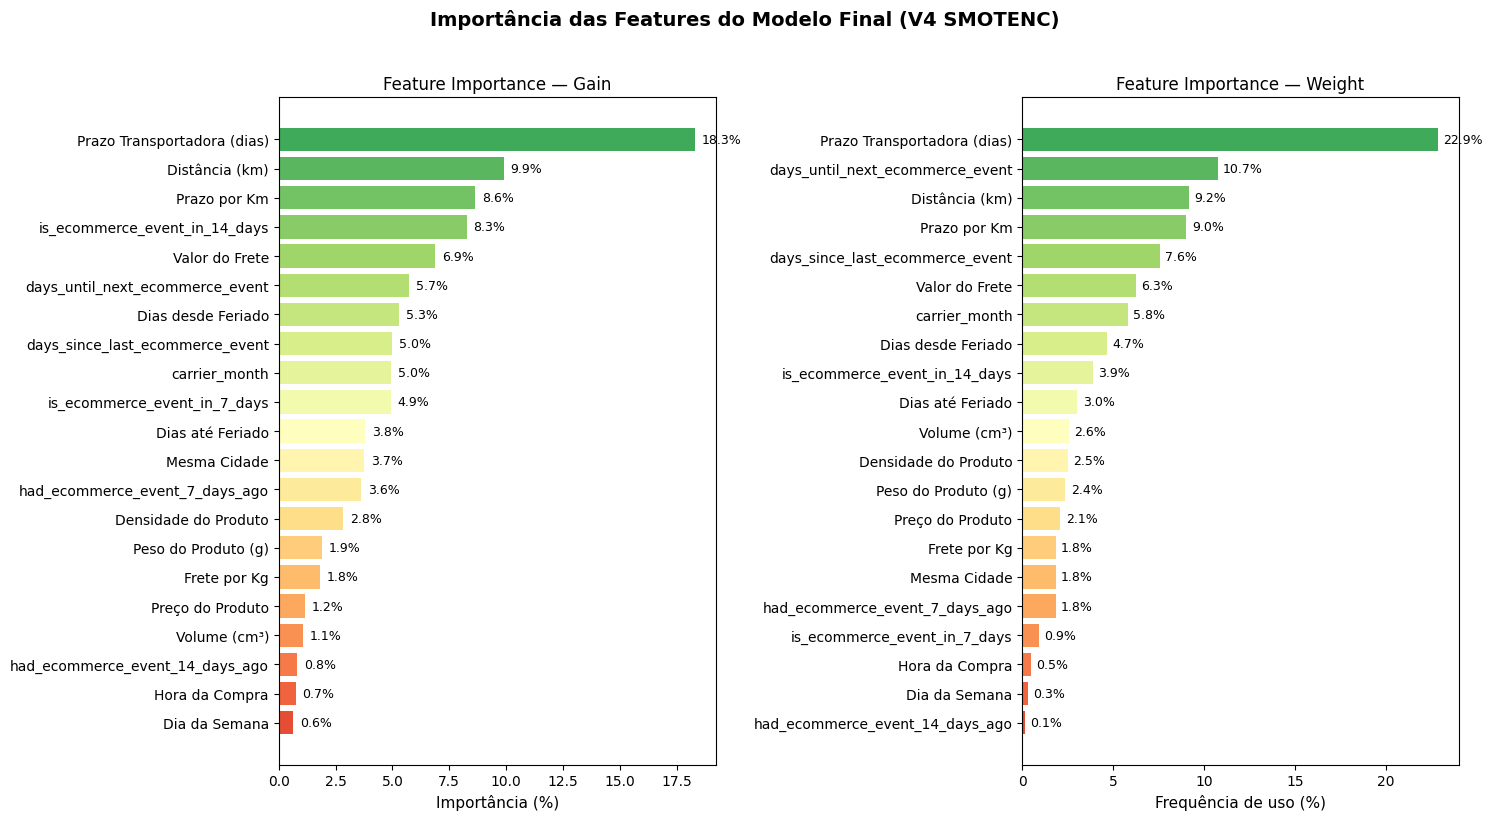

In [7]:
# Celula Extra: Grafico de Importancia das Features (Gain e Weight)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

importance_gain = model_v4.get_booster().get_score(importance_type="gain")
importance_weight = model_v4.get_booster().get_score(importance_type="weight")

df_imp = pd.DataFrame({
    "feature": list(importance_gain.keys()),
    "gain": list(importance_gain.values()),
}).sort_values("gain", ascending=True)

df_imp["weight"] = df_imp["feature"].map(importance_weight).fillna(0)

df_imp["gain_pct"] = df_imp["gain"] / df_imp["gain"].sum() * 100
df_imp["weight_pct"] = df_imp["weight"] / df_imp["weight"].sum() * 100

rename_map = {
    "prazo_transportadora_dias": "Prazo Transportadora (dias)",
    "distance_km": "Distância (km)",
    "freight_value": "Valor do Frete",
    "price": "Preço do Produto",
    "product_weight_g": "Peso do Produto (g)",
    "volume_cm3": "Volume (cm³)",
    "same_city": "Mesma Cidade",
    "seller_city": "Cidade do Vendedor",
    "customer_city": "Cidade do Cliente",
    "prazo_por_km": "Prazo por Km",
    "frete_por_kg": "Frete por Kg",
    "densidade_produto": "Densidade do Produto",
    "purchase_hour": "Hora da Compra",
    "purchase_day_of_week": "Dia da Semana",
    "category_name": "Categoria do Produto",
    "days_until_next_holiday": "Dias até Feriado",
    "days_since_last_holiday": "Dias desde Feriado",
    "purchase_month": "Mês da Compra",
}
df_imp["label"] = df_imp["feature"].map(rename_map).fillna(df_imp["feature"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 8))

colors1 = plt.cm.RdYlGn(np.linspace(0.15, 0.85, len(df_imp)))
ax1.barh(df_imp["label"], df_imp["gain_pct"], color=colors1)
ax1.set_xlabel("Importância (%)", fontsize=11)
ax1.set_title("Feature Importance — Gain", fontsize=12)
for i, val in enumerate(df_imp["gain_pct"]):
    ax1.text(val + 0.3, i, f"{val:.1f}%", va="center", fontsize=9)

df_imp2 = df_imp.sort_values("weight_pct", ascending=True)
colors2 = plt.cm.RdYlGn(np.linspace(0.15, 0.85, len(df_imp2)))
ax2.barh(df_imp2["label"], df_imp2["weight_pct"], color=colors2)
ax2.set_xlabel("Frequência de uso (%)", fontsize=11)
ax2.set_title("Feature Importance — Weight", fontsize=12)
for i, val in enumerate(df_imp2["weight_pct"]):
    ax2.text(val + 0.3, i, f"{val:.1f}%", va="center", fontsize=9)

plt.suptitle("Importância das Features do Modelo Final (V4 SMOTENC)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


In [8]:
# Célula de exportação para deploy: modelo + pré-processamento completo.
import pickle

raw_columns = [
    "purchase_date", "purchase_time", "carrier_datetime", "estimated_delivery_datetime",
    "price", "freight_value", "product_weight_g", "height_cm", "width_cm", "length_cm",
    "distance_km", "same_city", "customer_city", "seller_city", "category_name",
]

artefato_modelo = {
    "modelo": model_v4,
    "limiar": float(best_threshold_v4),
    "smote_ratio": float(best_smote_ratio_v4),
    "feature_names": list(X_train.columns),
    "num_cols": num_cols,
    "cat_cols": cat_cols,
    "scaler": scaler,
    "schema_version": 4,
    "inference_moment": "carrier_collection",
    "raw_columns": raw_columns,
    "ecommerce_events": [
        "mothers_day", "fathers_day", "children_day",
        "black_friday", "cyber_monday", "christmas",
    ],
}

with open("xgboost_lastmile_model_v4_smotenc_corrigido.pkl", "wb") as file:
    pickle.dump(artefato_modelo, file)

print("[Exportação] Artefato completo salvo: xgboost_lastmile_model_v4_smotenc_corrigido.pkl")


[Exportação] Artefato completo salvo: xgboost_lastmile_model_v4_smotenc_corrigido.pkl


In [9]:
# Celula 9: Diagnostico detalhado por faixas de prazo da transportadora (Treino vs Teste)
df_diag_train = pd.DataFrame({
    "dias": X_train["prazo_transportadora_dias"].values,
    "atraso": y_train.values,
    "pred_modelo": y_pred_v4_train,
})

df_diag_test = pd.DataFrame({
    "dias": X_test["prazo_transportadora_dias"].values,
    "atraso": y_test.values,
    "pred_modelo": y_pred_v4_test,
})

def classificar_macro(d):
    if d < 0:
        return "< 0 dias (Ja atrasado na coleta)"
    elif d == 0:
        return "0 dias (Vence no dia da coleta)"
    else:
        return "> 0 dias (Com prazo restante)"

ordem_macro = ["< 0 dias (Ja atrasado na coleta)", "0 dias (Vence no dia da coleta)", "> 0 dias (Com prazo restante)"]
df_diag_train["macro"] = pd.Categorical(df_diag_train["dias"].map(classificar_macro), categories=ordem_macro, ordered=True)
df_diag_test["macro"] = pd.Categorical(df_diag_test["dias"].map(classificar_macro), categories=ordem_macro, ordered=True)

def resumo_macro(df_d, prefixo):
    grp = df_d.groupby("macro", observed=False).agg(
        pedidos=("atraso", "count"),
        atrasos=("atraso", "sum"),
    )
    total_ped = len(df_d)
    total_atr = df_d["atraso"].sum()
    res = pd.DataFrame(index=grp.index)
    res[f"{prefixo}: Pedidos"] = grp["pedidos"]
    res[f"{prefixo}: % Total"] = (grp["pedidos"] / total_ped * 100).round(2)
    res[f"{prefixo}: Atrasos"] = grp["atrasos"]
    res[f"{prefixo}: % Atrasos"] = (grp["atrasos"] / total_atr * 100).round(2)
    res[f"{prefixo}: Taxa Atraso (%)"] = (grp["atrasos"] / grp["pedidos"].replace(0, np.nan) * 100).fillna(0).round(2)
    return res

print("=" * 120)
print("1. RESUMO MACRO: PEDIDOS COM PRAZO ESGOTADO (< 0 DIAS E 0 DIAS) VS COM PRAZO RESTANTE (> 0 DIAS)")
print("=" * 120)
df_macro_comp = pd.concat([resumo_macro(df_diag_train, "Treino"), resumo_macro(df_diag_test, "Teste")], axis=1)
display(df_macro_comp)


1. RESUMO MACRO: PEDIDOS COM PRAZO ESGOTADO (< 0 DIAS E 0 DIAS) VS COM PRAZO RESTANTE (> 0 DIAS)


,Treino: Pedidos,Treino: % Total,Treino: Atrasos,Treino: % Atrasos,Treino: Taxa Atraso (%),Teste: Pedidos,Teste: % Total,Teste: Atrasos,Teste: % Atrasos,Teste: Taxa Atraso (%)
macro,,,,,,,,,,
< 0 dias (Ja atrasado na coleta),0,0.00,0,0.00,0.00,0,0.00,0,0.00,0.00
0 dias (Vence no dia da coleta),35,0.12,35,2.65,100.00,64,1.28,64,12.83,100.00
> 0 dias (Com prazo restante),28568,99.88,1287,97.35,4.51,4936,98.72,435,87.17,8.81
